In [1]:
import polars as pl
import pandas as pd
from scipy.stats import lognorm, truncnorm
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_intens = pd.read_excel("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-2-6-10h16_intensites_matieres_RE2020.xlsx")

In [3]:
df_filtered = df_intens[(df_intens["usage"]=="Bureau") & (df_intens["produit"]=="{'nomenclature_inies_1': 'Produits de construction', 'nomenclature_inies_2': 'Structure / maçonnerie / gros œuvre / charpente', 'nomenclature_inies_3': 'Fondations ', 'nomenclature_inies_4': 'Béton armé', 'nomenclature_inies_5': None, 'unite_uf_txt': 'm³', 'dve': 100.0}")]

In [62]:
to_fit = df_filtered["quant_surf"]
shape = df_filtered["shape"]
scale = df_filtered["scale"]
loc = df_filtered["loc"]

In [63]:
l = eval(to_fit[to_fit.index[0]])

In [64]:
x = np.linspace(lognorm.ppf(0.001, shape, loc, scale),
                lognorm.ppf(0.999, shape, loc, scale), 500).flatten()
y = lognorm.pdf(x, shape, loc, scale).flatten()

(-0.01, 0.7)

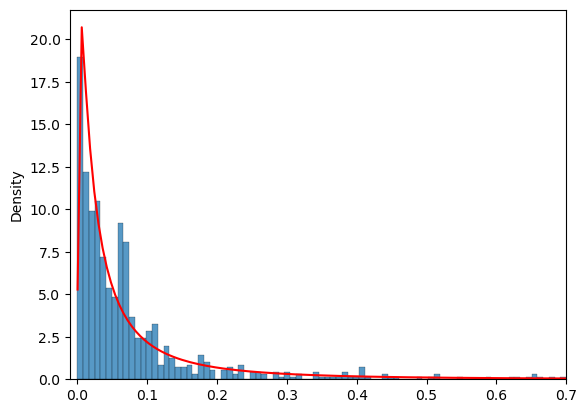

In [70]:
fig, ax = plt.subplots()
sns.histplot(l,stat="density",bins = 200)
sns.lineplot(x=x,y=y,color = "red")
ax.set_xlim(-0.01,0.7)


# Tirages sans brightway

In [4]:
df_int_mat = pl.read_excel("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-2-6-10h16_intensites_matieres_RE2020.xlsx")
df_int_cons = pl.read_excel("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-5-8-9h20_intensites_consos_RE2020.xlsx")
df_pre_run_prod = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-5-9-8h33_MC_runs/scores.parquet")
df_pre_run_cons = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-5-9-11h16_MC_runs/scores.parquet")

In [5]:
usages = df_int_mat["usage"].unique().to_list()

In [6]:
def get_name(prod_dict_str,nb_nom=1) :
    """
    Retourne le nom d'une nomenclature inies, plus ou moins long en fonction de nb_nom.

    Args:
        prod_dict (dict): nomenclature INIES dans un dictionnaire, avec unité de l'uf et dve
        nb_nom (int, optional): nombre de sous-nomenclature mise dans le nom. Defaults to 1.

    Returns:
        string : "nom" du produit, c'est à dire la sous-nomenclature la plus petite qui n'est pas None, 
            que précède les nomenclatures supérieures si nb_nom >1
    """
    prod_dict = eval(prod_dict_str)
    tmp = [v for k,v in prod_dict.items() if v is not None and "nomenclature" in k]
    if tmp :
        return "_".join(tmp[-nb_nom:])

    else :
        return None

def get_unit(prod_dict_str):
    prod_dict = eval(prod_dict_str)
    unit = prod_dict["unite_uf_txt"]
    return unit
    
def get_dve(prod_dict_str):
    prod_dict = eval(prod_dict_str)
    dve_str = str(prod_dict["dve"])[:-2]
    return dve_str
    
def get_code(name,unit,dve_str):
    return "_".join([name.lower(),unit,dve_str])


In [7]:

df_int_mat = df_int_mat.with_columns(
    pl.col("produit").map_elements(lambda x: get_name(x, 2), return_dtype=pl.String).alias("name"),
    pl.col("produit").map_elements(get_unit, return_dtype=pl.String).alias("unit"),
    pl.col("produit").map_elements(get_dve, return_dtype=pl.String).alias("dve"),
).filter(
    pl.col("name").is_not_null() & 
    pl.col("unit").is_not_null() & 
    pl.col("dve").is_not_null()
)


df_int_mat = df_int_mat.with_columns(
    pl.struct([pl.col("name"), pl.col("unit"), pl.col("dve")]).map_elements(
        lambda x: get_code(x["name"], x["unit"], x["dve"]),
        return_dtype=pl.String
    ).alias("code")
)

In [8]:
size = df_pre_run_prod["iteration"].max()+1
res={ u : np.empty([1,size]) for u in usages}
no_match = {u : [] for u in usages}
low_factor = 0.1
high_factor = 10


for u in usages :
    df_filtered = df_int_mat.filter(pl.col("usage")==u)
    prod_list = df_filtered["code"].to_list()
    for prod in prod_list :
        i = df_pre_run_prod.filter(pl.col("demand")== prod)["score"].to_numpy()
        if i.shape[0] == 0:
            no_match[u].append(prod)
            continue

        tmp = df_filtered.filter(pl.col("code")== prod)
        p = tmp["param_bernoulli"][0]
        mu = np.log(tmp["scale"][0])
        sigma = tmp["shape"][0]
        try : 
            quant_surf_list = eval(tmp["quant_surf"][0])
        except SyntaxError: 
            quant_surf_list = eval(f"{tmp["quant_surf"][0]}]")

        min_quant = np.min(quant_surf_list)
        max_quant = np.max(quant_surf_list)
        low   = min_quant*low_factor
        high  = max_quant*high_factor

        b = np.random.binomial(n=1, p=p, size=size)

        if sigma <= 0:
        # Degenerate case: no variance, just use the fixed mean
            l = np.full(size, np.exp(mu))
        else:
            a       = (np.log(low) - mu) / sigma
            b_trunc = (np.log(high) - mu) / sigma
            l = np.exp(truncnorm.rvs(a, b_trunc, loc=mu, scale=sigma, size=size))

        to_add = b*l*i
        res[u] = res[u] + to_add

/tmp/ipykernel_159708/2952521979.py:37: RuntimeWarning: divide by zero encountered in log
  a       = (np.log(low) - mu) / sigma


In [9]:
conso_dict ={
    "bois" :'Consommations_bois',
    "eau" : 'consommations_eau',
    "gaz" : 'Consommations_gaz',
    "reseau" : 'consommations_reseau',
    "elec" : 'consommations_electricite'
    }

df_int_cons = df_int_cons.with_columns(
    pl.col("produit").map_elements(
        lambda x : conso_dict[x.split("_")[1]],
        return_dtype = pl.String
    ).alias("code")
)

In [10]:

for u in usages :
    df_filtered = df_int_cons.filter(pl.col("usage")==u)
    conso_list = df_filtered["code"].to_list()
    for conso in conso_list :
        i = df_pre_run_cons.filter(pl.col("demand")== conso)["score"].to_numpy()
        if i.shape[0] == 0:
            no_match[u].append(conso)
            continue

        tmp = df_filtered.filter(pl.col("code")== conso)
        p = tmp["param_bernoulli"][0]
        mu = np.log(tmp["scale"][0])
        sigma = tmp["shape"][0]
        
        b = np.random.binomial(n=1, p=p, size=size)
        l =  np.random.lognormal(mean=mu, sigma=sigma, size=size)
        to_add = b*l*i
        res[u] = res[u] + to_add

In [15]:
import pickle
with open("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/arch_mi_based_1000_gwp100.pkl", 'wb') as file:
    pickle.dump(res, file)

# Tracés SETAC POSTER

In [268]:
to_graph = pl.DataFrame({ k : v[0,:] for k,v in res.items()}).unpivot(on=usages, variable_name="usage",value_name="score").filter(~pl.col("usage").str.contains("Enseignement"))

In [269]:
from cmcrameri import cm

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": "Computer Modern",
})

cmap = cm.berlin

(0.0, 6000.0)

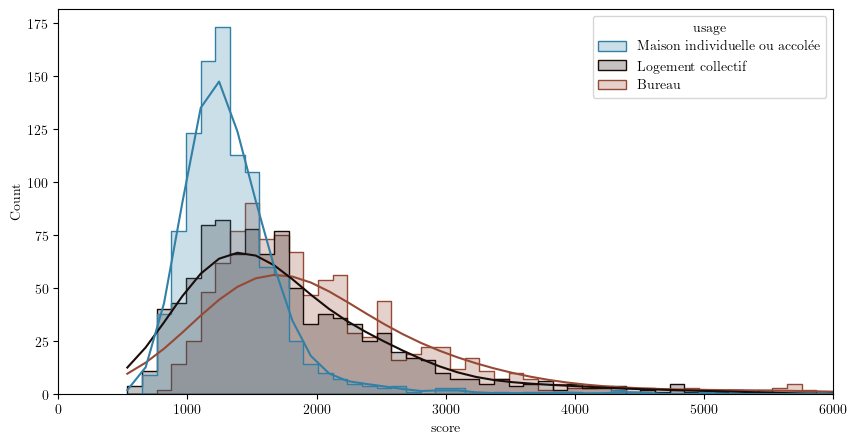

In [270]:
fig, ax = plt.subplots(figsize = (10,5))

n_hues = len(df_filtered['usage'].unique())

palette = list(cmap(np.linspace(0.2, 0.8, n_hues)))
sns.histplot(
    data = to_graph,
    x= "score",
    hue = "usage",
    element="step", 
    ax=ax,
    palette= palette,
    kde = True
    )
ax.set_xlim(0,6000)

In [243]:
to_graph.filter(pl.col("usage")=="Maison individuelle ou accolée").describe()

statistic,usage,score
str,str,f64
"""count""","""1000""",1000.0
"""null_count""","""0""",0.0
"""mean""",null,1363.387633
"""std""",null,488.563716
"""min""","""Maison individuelle ou accolée""",665.744987
"""25%""",null,1105.11853
"""50%""",null,1277.254271
"""75%""",null,1502.477349
"""max""","""Maison individuelle ou accolée""",6922.887454


In [246]:
import bw2data as bd
import bw2io as bi
import bw2calc as bc
import bw2analyzer as bwa
bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")

In [247]:
bd.databases

Databases dictionary with 11 object(s):
	2026-3-19-11h18_processes_RE2020
	2026-4-21_consumptions_processes
	2026-4-22-15h1_buildings_RE2020
	2026-4-22-16h25_archetypes_RE2020_BB
	2026-4-22-16h7_buildings_cons_RE2020
	2026-4-23-18h10_archetypes_RE2020_PRB
	2026-5-7-20h29_archetypes_RE2020_MIB
	2026-5-7-20h29_bernoulli_RE2020
	ecoinvent-3.11-biosphere
	ecoinvent-3.11-cutoff
	pr_based_arch_alamain

In [249]:
cons_db = bd.Database("2026-4-21_consumptions_processes")

In [250]:
[a for a in cons_db]

['Consommations_réseau_gaz' (kilowatt hour, FR, ('custom_process',)),
 'Consommations_réseau_autres' (kilowatt hour, FR, ('custom_process',)),
 'Consommations_réseau_UVE' (kilowatt hour, FR, ('custom_process',)),
 'Consommations_électricité' (kilowatt hour, FR, ('custom_process',)),
 'Consommations_gaz' (kilowatt hour, FR, ('custom_process',)),
 'Consommations_bois' (kilowatt hour, FR, ('custom_process',)),
 'Consommations_eau' (cubic meter, FR, ('custom_process',)),
 'Consommations_réseau' (kilowatt hour, FR, ('custom_process',))]

In [252]:
df_pre_run_cons["indicator"].unique().to_list()

['ecoinvent-3.11 | EF v3.1 | climate change | global warming potential (GWP100)']

In [264]:
df = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-5-5-20h1_MC_runs/scores.parquet")

In [265]:
df

iteration,demand,indicator,score
u32,str,str,f64
0,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",690.328378
1,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",573.632367
2,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",781.955657
3,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",440.142244
4,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",784.712585
…,…,…,…
995,"""Planchers_Acier / béton""","""ecoinvent-3.11 | EF v3.1 | cli…",74.300773
996,"""Planchers_Acier / béton""","""ecoinvent-3.11 | EF v3.1 | cli…",65.81544
997,"""Planchers_Acier / béton""","""ecoinvent-3.11 | EF v3.1 | cli…",65.273214


In [262]:
df["indicator"].unique().to_list()

['ecoinvent-3.11 | EF v3.1 | climate change | global warming potential (GWP100)']

In [263]:
arch_db.name

'2026-4-22-16h25_archetypes_RE2020_BB'

In [266]:
prod_db = bd.Database("2026-4-21_consumptions_processes")
to_consider = ["'Consommations_électricité' (kilowatt hour, FR, ('custom_process',))",
"'Consommations_gaz' (kilowatt hour, FR, ('custom_process',))",
"'Consommations_bois' (kilowatt hour, FR, ('custom_process',))",
"'Consommations_eau' (cubic meter, FR, ('custom_process',))",
"'Consommations_réseau' (kilowatt hour, FR, ('custom_process',))"]
processes_list = [p for p in prod_db if str(p) in to_consider]

In [267]:
processes_list

['Consommations_électricité' (kilowatt hour, FR, ('custom_process',)),
 'Consommations_bois' (kilowatt hour, FR, ('custom_process',)),
 'Consommations_réseau' (kilowatt hour, FR, ('custom_process',)),
 'Consommations_eau' (cubic meter, FR, ('custom_process',)),
 'Consommations_gaz' (kilowatt hour, FR, ('custom_process',))]

# Tracés SETAC - comparaisons méthodes

In [10]:
df_mi = pl.DataFrame({ k : v[0,:] for k,v in res.items()}).unpivot(on=usages, variable_name="usage",value_name="score").filter(~pl.col("usage").str.contains("Enseignement"))
df_bb = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-5-8-4h3_MC_runs/scores.parquet")

In [11]:
to_graph = pl.DataFrame(schema={"use" : pl.String, "score" : pl.Float64, "approach" : pl.String})

In [12]:
to_add_bb = pl.DataFrame({"use" : [d.lower() for d in df_bb["demand"].to_list()], "score" : df_bb["score"].to_list(), "approach" : ["Buildings based" for _ in range(len(df_bb))]})
to_add_mi = pl.DataFrame({
    "use" : [u.strip().lower().replace(" ", "_") for u in df_mi["usage"].to_list()],
    "score" : df_mi["score"].to_list(),
    "approach" : ["Material intensity based" for _ in range(len(df_mi))]
    })


In [13]:
to_graph = pl.concat([to_add_bb, to_add_mi])

In [67]:
# use = "maison_individuelle_ou_accolée"
# use = "logement_collectif"
use = "bureau"

(500.0, 4000.0)

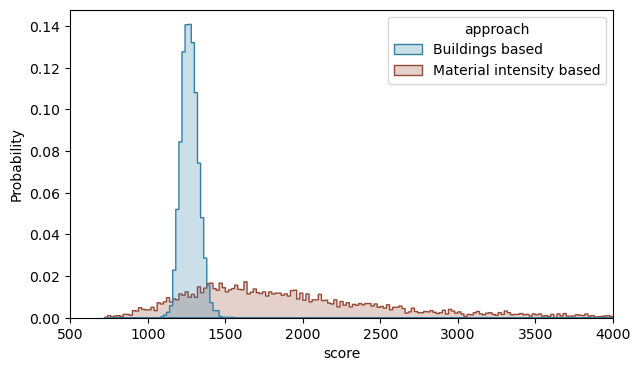

In [68]:
from cmcrameri import cm

# plt.rcParams.update({
#     "text.usetex": True,
#     "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
#     "font.family": "serif",
#     "font.serif": "Computer Modern",
# })

cmap = cm.berlin
fig, ax = plt.subplots(figsize = (7,4))

n_hues = len(to_graph['approach'].unique())

palette = list(cmap(np.linspace(0.2, 0.8, n_hues)))
sns.histplot(
    data = to_graph.filter(pl.col("use")==use),
    x= "score",
    hue = "approach",
    element="step",
    stat = "probability",
    common_norm=False, 
    ax=ax,
    binwidth = 20,
    palette= palette,
    # kde = True
    )
ax.set_xlim(500,4000)

# fig.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/SETAC Europe 2025/{use}_{len(to_graph.filter(pl.col("use")=="bureau",pl.col("approach")=="Buildings based"))}.pdf",dpi = 300)

In [16]:
for u  in to_graph["use"].unique().to_list() :
    for app in to_graph["approach"].unique().to_list() :
        print(u,app, to_graph.filter(pl.col("use")==u,pl.col("approach")==app).describe())

bureau Buildings based shape: (9, 4)
┌────────────┬────────┬─────────────┬─────────────────┐
│ statistic  ┆ use    ┆ score       ┆ approach        │
│ ---        ┆ ---    ┆ ---         ┆ ---             │
│ str        ┆ str    ┆ f64         ┆ str             │
╞════════════╪════════╪═════════════╪═════════════════╡
│ count      ┆ 100    ┆ 100.0       ┆ 100             │
│ null_count ┆ 0      ┆ 0.0         ┆ 0               │
│ mean       ┆ null   ┆ 1273.300305 ┆ null            │
│ std        ┆ null   ┆ 54.259984   ┆ null            │
│ min        ┆ bureau ┆ 1174.177637 ┆ Buildings based │
│ 25%        ┆ null   ┆ 1237.246023 ┆ null            │
│ 50%        ┆ null   ┆ 1270.529864 ┆ null            │
│ 75%        ┆ null   ┆ 1298.972003 ┆ null            │
│ max        ┆ bureau ┆ 1435.864693 ┆ Buildings based │
└────────────┴────────┴─────────────┴─────────────────┘
bureau Material intensity based shape: (9, 4)
┌────────────┬────────┬─────────────┬──────────────────────────┐
│ statistic 

# Distribution d'écart à la moyenne

In [14]:
import bw2data as bd
import bw2io as bi
import bw2calc as bc
import bw2analyzer as bwa
import polars as pl 
from tqdm import tqdm
from datetime import datetime

bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")

00:55:02+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [15]:
from archetypes_re2020.archetypes.buildings_based_archetypes_db import load_parquet_data, INPUT_PATH
from archetypes_re2020.data.source import INPUT_PATHS

df_buildings = pl.read_csv(
    source=INPUT_PATHS["BUILDINGS"], ignore_errors=True
    )

In [16]:
def chunk_list(lst, chunk_size):
    for i in range(0, len(lst), chunk_size):
        yield lst[i:i + chunk_size]

In [17]:
build_db = bd.Database("2026-4-22-16h7_buildings_cons_RE2020")

In [18]:
gwps = [m for m in bd.methods if "gwp" in str(m).lower() and "no LT" not in str(m) and "EF v3.1" in str(m) and "fossil" not in str(m) and "biogenic" not in str(m) and "land" not in str(m) and "EN15804" not in str(m)]

In [7]:
import gc
buildings_energy_res = {}
config ={"impact_categories" : gwps}

for chunk in tqdm(chunk_list(list(build_db),2000)):
    demands = {
        b["name"] : {b.id : 1.0 }
        for b in chunk
        }
    data_objs = bd.get_multilca_data_objs(
        functional_units=demands,
        method_config=config
        )
    lca = bc.MultiLCA(demands=demands, method_config=config, data_objs=data_objs)
    lca.lci()
    lca.lcia()
    buildings_energy_res |= lca.scores
    del lca
    del demands
    gc.collect()

import pickle
today = datetime.today()
with open(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/{today.year}-{today.month}-{today.day}_res_per_building_cons.pkl", "wb") as f:
    pickle.dump(buildings_energy_res, f)

40it [1:18:53, 118.34s/it]


In [19]:
import pickle

with open("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-5-9_res_per_building_cons.pkl", "rb") as f:
    buildings_energy_res = pickle.load(f)

In [20]:
df_buildings = df_buildings.with_columns(
    pl.struct([pl.col("projet_id"),pl.col("batiment_index")]).map_elements(
        lambda s: "_".join([str(s["projet_id"]),str(s["batiment_index"])]),
        return_dtype = pl.String
    ).alias("lca_id")
)

In [21]:
dict_buildings_use = (
    df_buildings
    .select(["lca_id", "usage_principal_1_txt"])
    .rows_by_key(key=["lca_id"])
)

In [22]:
dict_buildings_use = { k: v[0][0] for k, v in dict_buildings_use.items()}

In [23]:
dict_buildings_use

{'344397_1': 'Maison individuelle ou accolée',
 '344398_1': 'Bureau',
 '344399_1': 'Maison individuelle ou accolée',
 '344400_1': 'Maison individuelle ou accolée',
 '344403_1': 'Maison individuelle ou accolée',
 '344404_1': 'Maison individuelle ou accolée',
 '344406_1': 'Maison individuelle ou accolée',
 '344408_1': 'Logement collectif',
 '344408_2': 'Logement collectif',
 '344408_3': 'Logement collectif',
 '344408_4': 'Logement collectif',
 '344408_5': 'Logement collectif',
 '344409_1': 'Maison individuelle ou accolée',
 '344410_1': 'Maison individuelle ou accolée',
 '344411_1': 'Maison individuelle ou accolée',
 '344412_1': 'Maison individuelle ou accolée',
 '344413_1': 'Maison individuelle ou accolée',
 '344414_1': 'Maison individuelle ou accolée',
 '344415_1': 'Maison individuelle ou accolée',
 '344416_1': 'Maison individuelle ou accolée',
 '344418_1': 'Maison individuelle ou accolée',
 '344419_1': 'Maison individuelle ou accolée',
 '344420_1': 'Maison individuelle ou accolée',
 '3

In [40]:
res_dict = { k[1] :v for k,v in buildings_energy_res.items()}

In [41]:
df_res = pl.DataFrame(res_dict).unpivot(variable_name = "building", value_name = "score")

In [42]:
def get_use(building) :
    try :
        res = dict_buildings_use[building]
    except KeyError : 
        res = None

    return res

df_res = df_res.with_columns(
    pl.col("building").map_elements(
        lambda x : get_use(x),
        return_dtype=pl.String
    ).alias("use")
)

In [43]:
usages = df_res["use"].unique().drop_nulls()
dict_mu = {u : 0 for u in usages}
for u in usages: 
    dict_mu[u] = df_res.filter(pl.col("use")==u)["score"].mean()

In [28]:
dict_mu

{'Bureau': 1381.3849572516003,
 'Logement collectif': 1216.4026188209305,
 'Enseignement primaire': 976.6062195467249,
 'Enseignement secondaire (partie jour)': 914.8520645190339,
 'Maison individuelle ou accolée': 1111.4086201047119}

In [44]:
def get_mu(use) :
    try :
        res = dict_mu[use]
    except KeyError :
        res = None
    return res
df_res = df_res.with_columns(
    pl.col("use").map_elements(
        lambda x : get_mu(x),
        return_dtype = pl.Float64
    ).alias("mu")
)

In [30]:

df_res = df_res.drop_nulls()

In [45]:
df_res = df_res.with_columns(
    epsilon = pl.col("score") - pl.col("mu")
)

In [46]:
df_res.filter(pl.col("use") == "Maison individuelle ou accolée").describe()

statistic,building,score,use,mu,epsilon
str,str,f64,str,f64,f64
"""count""","""77296""",77296.0,"""77296""",77296.0,77296.0
"""null_count""","""0""",0.0,"""0""",0.0,0.0
"""mean""",null,1111.40862,null,1111.40862,4.6313e-14
"""std""",null,375.311523,null,0.0,375.311523
"""min""","""343654_1""",234.795036,"""Maison individuelle ou accolée""",1111.40862,-876.613584
"""25%""",null,960.981683,null,1111.40862,-150.426937
"""50%""",null,1102.472347,null,1111.40862,-8.936273
"""75%""",null,1250.62609,null,1111.40862,139.21747
"""max""","""625650_1""",57986.293684,"""Maison individuelle ou accolée""",1111.40862,56874.885064


In [32]:
usages_limited = [u for u in usages if "Enseignement" not in u]

In [47]:
def remove_outliers(l) :
    q3, q1 = np.percentile(l, [75 ,25])
    iqr = q3-q1
    low = q1-1.5*iqr
    high = q3+1.5*iqr
    return [e for e in l if (e>low) & (e<high)]

In [48]:
from scipy.stats import truncnorm, norm
import numpy as np

low_factor = 1
high_factor = 1


dict_epsilon = {u : [] for u in usages_limited}
for u in usages_limited :
    
    tmp = remove_outliers(df_res.filter(pl.col("use")== u)["epsilon"].to_list())

    q3, q1 = np.percentile(tmp, [75 ,25])
    iqr = q3-q1
    lower,upper = low_factor*(q1-1.5*iqr),high_factor**(q3+1.5*iqr)
    mu,std = norm.fit(tmp)
    a = (lower - mu) / std
    b = (upper - mu) / std
    a_fit, b_fit, mu_fit, std_fit = truncnorm.fit(tmp, fa=a, fb=b)
    dict_epsilon[u] = truncnorm.rvs(a_fit, b_fit, mu_fit, std_fit, size=5000)



In [49]:
dict_epsilon = { "_".join(k.lower().split(" ")) : v for k,v in dict_epsilon.items()}

In [50]:
dict_epsilon

{'bureau': array([-153.86979846,  575.87428569,  597.38546505, ...,   34.31374288,
        -483.32494997, -910.24138625]),
 'logement_collectif': array([ 630.01277803,  534.96274935, -313.74002658, ...,  568.17385023,
         533.58931632,  580.38152667]),
 'maison_individuelle_ou_accolée': array([-8715.62527895,  -326.93825857, -6086.57236897, ...,
        -8514.8564531 , -2273.68425689,    87.49343108])}

In [51]:
df_bb_source = to_graph.filter(pl.col("approach")=="Buildings based")

In [52]:
to_add = {u : np.array(df_bb_source.filter(pl.col("use") == u)["score"].to_list()) for u in df_bb_source["use"].unique().to_list()}

In [53]:
dict_third_app = {u : dict_epsilon[u]+to_add[u] for u in to_add.keys()}

In [54]:
df_third_app = pl.DataFrame(dict_third_app).unpivot(variable_name = "use",value_name ="score")
df_third_app = df_third_app.with_columns(
    approach=pl.lit("Third approach")
)

In [55]:
df_third_app

use,score,approach
str,f64,str
"""bureau""",1037.585081,"""Third approach"""
"""bureau""",1784.837121,"""Third approach"""
"""bureau""",1802.379502,"""Third approach"""
"""bureau""",1546.819845,"""Third approach"""
"""bureau""",1869.413064,"""Third approach"""
…,…,…
"""logement_collectif""",1834.802377,"""Third approach"""
"""logement_collectif""",1537.299356,"""Third approach"""
"""logement_collectif""",1937.440988,"""Third approach"""


In [56]:
to_graph_all = pl.concat([to_graph,df_third_app])

In [72]:
np.mean(remove_outliers(to_graph_all.filter(pl.col("use")=="maison_individuelle_ou_accolée",pl.col("approach")=="Third approach")["score"].to_list()))

-4313.760822757593

In [62]:
use = "maison_individuelle_ou_accolée"
# use = "logement_collectif"
# use = "bureau"

ValueError: Maximum allowed size exceeded

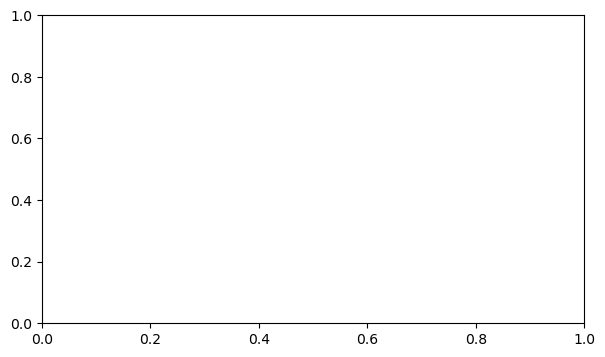

In [63]:
from cmcrameri import cm

# plt.rcParams.update({
#     "text.usetex": True,
#     "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
#     "font.family": "serif",
#     "font.serif": "Computer Modern",
# })

cmap = cm.berlin
fig, ax = plt.subplots(figsize = (7,4))

n_hues = len(to_graph_all['approach'].unique())

palette = list(cmap(np.linspace(0.2, 0.8, n_hues)))
sns.histplot(
    data = to_graph_all.filter(pl.col("use")==use),
    x= "score",
    hue = "approach",
    element="step",
    stat = "probability",
    common_norm=False, 
    ax=ax,
    binwidth = 20,
    palette= palette,
    # kde = True
    )
ax.set_xlim(500,4000)

# fig.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/SETAC Europe 2025/{use}_{len(to_graph.filter(pl.col("use")=="bureau",pl.col("approach")=="Buildings based"))}.pdf",dpi = 300)